In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# machine Learning

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
#from sklearn.file import joblib

In [13]:
df = pd.read_csv ("Wholesale customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [14]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [16]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [17]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [18]:
from sklearn.preprocessing import StandardScaler
X = df.drop('Fresh', axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print(X_scaled_df)

      Channel    Region      Milk   Grocery    Frozen  Detergents_Paper  \
0    1.448652  0.590668  0.523568 -0.041115 -0.589367         -0.043569   
1    1.448652  0.590668  0.544458  0.170318 -0.270136          0.086407   
2    1.448652  0.590668  0.408538 -0.028157 -0.137536          0.133232   
3   -0.690297  0.590668 -0.624020 -0.392977  0.687144         -0.498588   
4    1.448652  0.590668 -0.052396 -0.079356  0.173859         -0.231918   
..        ...       ...       ...       ...       ...               ...   
435 -0.690297  0.590668  0.848446  0.850760  2.075222         -0.566831   
436 -0.690297  0.590668 -0.592142 -0.757165  0.296561         -0.585519   
437  1.448652  0.590668  1.314671  2.348386 -0.543380          2.511218   
438 -0.690297  0.590668 -0.517536 -0.602514 -0.419441         -0.569770   
439 -0.690297  0.590668 -0.555924 -0.573227 -0.620094         -0.504888   

     Delicassen  
0     -0.066339  
1      0.089151  
2      2.243293  
3      0.093411  
4      1.

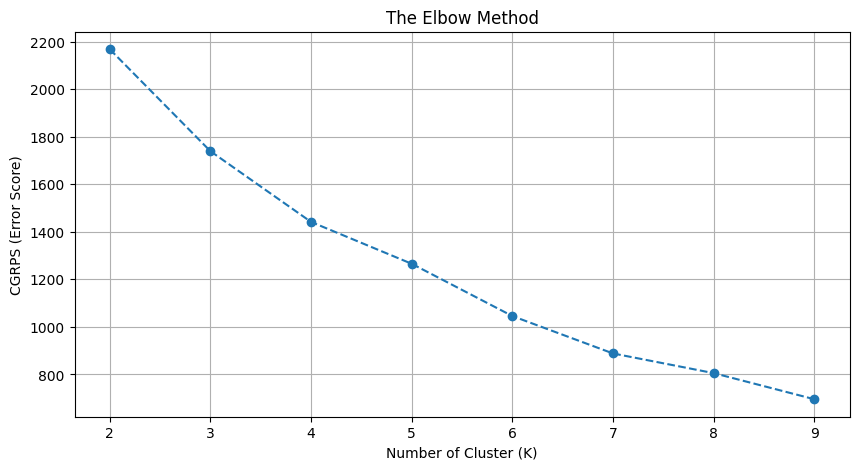

In [20]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

cgrps = []

for i in range(2, 10):
    Kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    Kmeans.fit(X_scaled)
    cgrps.append(Kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(2,10), cgrps, marker='o', linestyle='--')
plt.title("The Elbow Method")
plt.xlabel("Number of Cluster (K)")
plt.ylabel("CGRPS (Error Score)")
plt.grid(True)
plt.show()

In [23]:
# Initiate Kmeans with n_clusters.abs

Kmeans = KMeans (n_clusters=i, init='k-means++', random_state=42)
clusters = Kmeans.fit_predict(X_scaled)

df["cluster_group"] = clusters
df[['Region', 'cluster_group']].head()

,Region,cluster_group
0,3,0
1,3,0
2,3,0
3,3,8
4,3,0


In [25]:
# Analyzing the clusters

cluster_analysis = df.drop ('Region', axis=1).groupby('cluster_group').mean()
important_columns = ['Milk', 'Frozen', 'Grocery']
print(cluster_analysis[important_columns])

                       Milk        Frozen       Grocery
cluster_group                                          
0               7453.204301   1362.290323  11618.397849
1               2612.125654   1838.151832   3464.319372
2              53080.750000   3262.250000  60015.750000
3              12924.000000   1544.551724  18143.931034
4              43950.000000  36534.000000  20170.000000
5               3827.483333   2995.566667   4058.750000
6               9937.000000  47939.000000   7844.000000
7              17848.615385   1895.769231  35190.307692
8               5227.000000  10196.553191   5388.765957


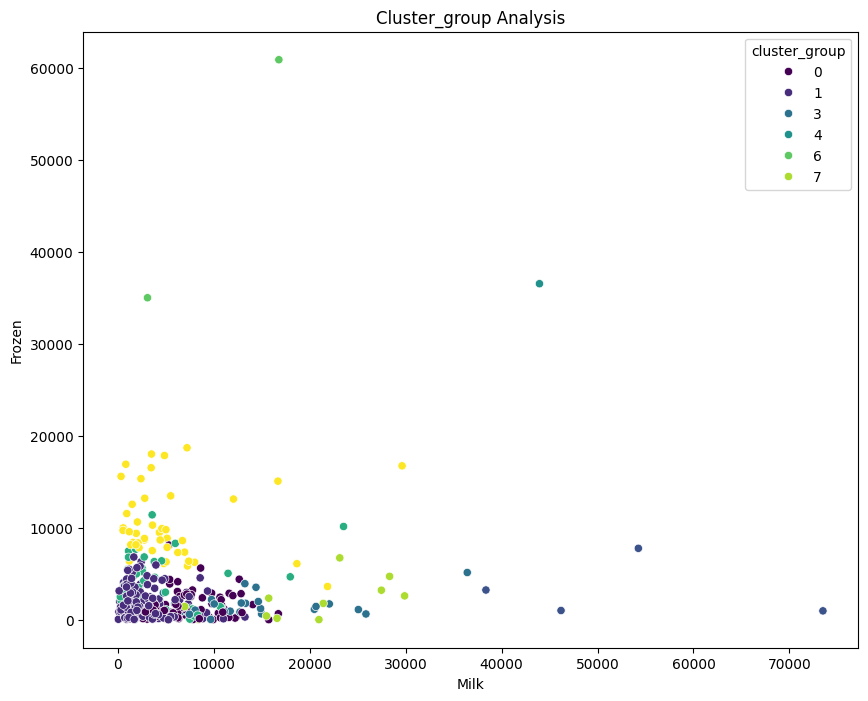

In [26]:
import seaborn as sns
plt.figure(figsize=(10,8))
sns.scatterplot(data=df, x='Milk', y='Frozen', hue='cluster_group', palette='viridis')
plt.title('Cluster_group Analysis')
plt.show()